# Comparación de modelos OLS · propiedades usadas

Se utiliza exclusivamente `data/train_transformado.csv`, generado en `2_Transformacion_PropUsadas.ipynb`.
`X` contiene las predictoras exportadas y `y` corresponde a `price_rub`.
`id`, `date_posted_dt` y `dataset_split` son auxiliares y no participan del modelo.
No se repiten transformaciones ni se alteran datos. Test queda reservado para la evaluación final.


In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown
paquete = next(c for p in (Path.cwd(), *Path.cwd().parents)
               for c in (p, p / "Ventas/Fase1_PropUsadas") if (c / "scripts/__init__.py").is_file())
if str(paquete) not in sys.path: sys.path.insert(0, str(paquete))
from scripts import baseline_ols as b
from scripts.almacenamiento_mlflow import SesionTemporal
from scripts.contrato_datasets import CARPETA_PROYECTO as base
sesion, cliente = SesionTemporal(), None
X, y, contexto = b.cargar_train(base)
print(f"Observaciones: {len(y):,} · Predictoras: {X.shape[1]} · Objetivo: price_rub (RUB)")


Observaciones: 37,984 · Predictoras: 177 · Objetivo: price_rub (RUB)


## Evolución de las variables

Las exclusiones son acumulativas. Los cinco modelos conservan las mismas observaciones y un intercepto; no se vuelve a transformar el dataset.


In [2]:
display(Markdown(b.evolucion_variables(X)))


| Experimento | Objetivo | Predictoras | Variables eliminadas acumuladas |
|---|---|---|---|
| 1 — Baseline_OLS_01 | price_rub | 177 | Ninguna |
| 2 — OLS_02_Log_Target | ln(price_rub) | 177 | Ninguna |
| 3 — OLS_03_Log_Sin_to_center_km | ln(price_rub) | 176 | to_center_km |
| 4 — OLS_04_Log_Sin_living_area | ln(price_rub) | 175 | to_center_km, living_area |
| 5 — OLS_05_Log_Sin_rooms | ln(price_rub) | 174 | to_center_km, living_area, rooms |

## Experimento 1 — Baseline_OLS_01

OLS con intercepto, las **177 predictoras** disponibles y `price_rub` en RUB, sin transformar el objetivo. El gráfico contrasta los precios observados y ajustados en Train.


In [3]:
with sesion.paso():
    m1 = b.ajustar_presentacion(X, y, contexto, 1)


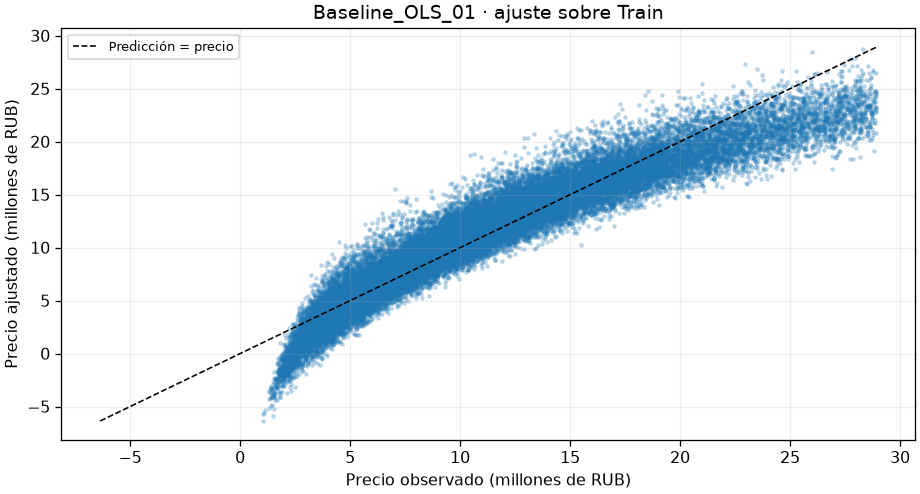

In [4]:
display(b.grafico_presentacion(m1))


In [5]:
display(Markdown(b.tabla_presentacion(m1)))


| Métrica | Baseline_OLS_01 |
|---|---|
| R² [RUB] | 0.893313 |
| R² ajustado [RUB] | 0.892814 |
| MAE (RUB) | 1,442,336.504 |
| RMSE (RUB) | 1,911,878.872 |
| AIC [RUB] | 1,206,920.461 |
| BIC [RUB] | 1,208,441.457 |
| VIF máximo | 102.584 |
| Número de condición | 19,159.166 |
| Breusch–Pagan (p) [RUB] | 0 |
| Jarque–Bera (p) [RUB] | 0 |

In [6]:
display(Markdown(b.interpretacion_presentacion(m1)))


El ajuste en Train alcanza R²=0.8933, con MAE=1,442,337 RUB y RMSE=1,911,879 RUB.  
VIF máximo=102.58 y número de condición=19159.2: hay colinealidad y sensibilidad numérica.  
Breusch–Pagan (p=0.00e+00) y Jarque–Bera (p=0.00e+00) señalan límites de homocedasticidad y normalidad.  
El próximo experimento evalúa ln(price_rub). Estas métricas de Train no establecen capacidad predictiva fuera de muestra.

In [7]:
with sesion.paso():
    cliente, confirmacion = b.registrar_presentacion(m1, sesion, cliente)
    display(Markdown(confirmacion))


**FINISHED** · [Baseline_OLS_01 en DagsHub](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/43e383e9b91d43efbdeda5ec1ec28f71)

## Experimento 2 — OLS_02_Log_Target

Referencia: **Baseline_OLS_01**. Se mantienen las mismas **177 predictoras** y se ajusta `ln(price_rub)`. La figura compara la distribución de errores absolutos en RUB. La inversa es `exp`, sin corrección de sesgo; puede afectar la estimación del precio esperado.


In [8]:
with sesion.paso():
    m2 = b.ajustar_presentacion(X, y, contexto, 2, anterior=m1)


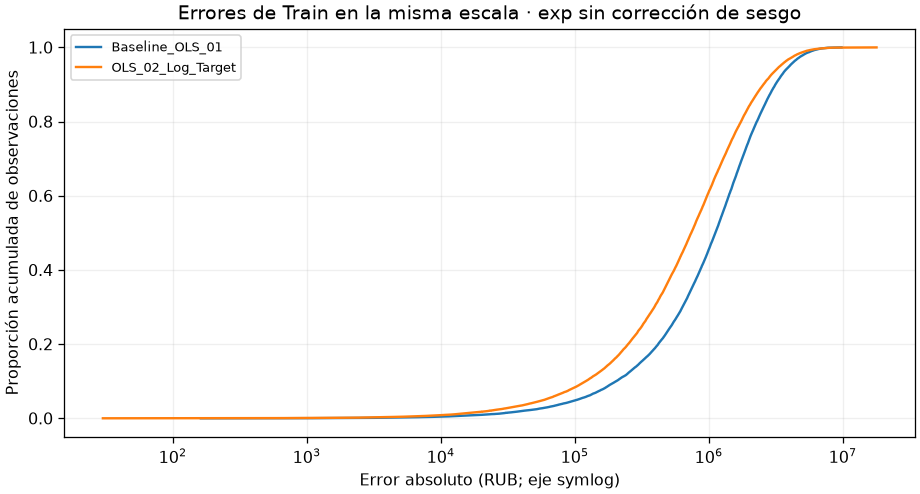

In [9]:
display(b.grafico_presentacion(m2))


In [10]:
display(Markdown(b.tabla_presentacion(m2)))


| Métrica | Baseline_OLS_01 | OLS_02_Log_Target | Δ nuevo − anterior |
|---|---|---|---|
| R² [RUB → ln(RUB)] | 0.893313 | 0.955694 | No comparable |
| R² ajustado [RUB → ln(RUB)] | 0.892814 | 0.955487 | No comparable |
| MAE (RUB) | 1,442,336.504 | 1,093,408.724 | -348,927.780 |
| RMSE (RUB) | 1,911,878.872 | 1,575,798.353 | -336,080.519 |
| AIC [RUB → ln(RUB)] | 1,206,920.461 | -54,582.348 | No comparable |
| BIC [RUB → ln(RUB)] | 1,208,441.457 | -53,061.352 | No comparable |
| VIF máximo | 102.584 | 102.584 | 0 |
| Número de condición | 19,159.166 | 19,159.166 | 0 |
| Breusch–Pagan (p) [RUB → ln(RUB)] | 0 | 1.196e-150 | No comparable |
| Jarque–Bera (p) [RUB → ln(RUB)] | 0 | 1.394e-40 | No comparable |

R², R² ajustado, AIC, BIC y pruebas de residuos describen respuestas en escalas distintas; no se comparan entre estos dos ajustes.

In [11]:
display(Markdown(b.interpretacion_presentacion(m2)))


En Train, MAE cambia -24.19184 % y RMSE -17.57855 % en RUB frente al modelo anterior.  
La transformación del objetivo cambia el peso relativo de los errores; VIF y condicionamiento permanecen iguales porque X no cambia.  
Persisten heterocedasticidad y desviaciones de normalidad (BP p=1.20e-150; JB p=1.39e-40).  
exp(E[ln(precio)|X]) no equivale a E[precio|X]; la inversa sin corrección puede subestimar el precio esperado.  
Se examina a continuación to_center_km para reducir colinealidad. AIC, BIC y R² nativos no se comparan con la baseline en RUB.

In [12]:
with sesion.paso():
    cliente, confirmacion = b.registrar_presentacion(m2, sesion, cliente)
    display(Markdown(confirmacion))


**FINISHED** · [OLS_02_Log_Target en DagsHub](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/2dfd0a0d8d7a41818305f1137704b26e)

## Experimento 3 — OLS_03_Log_Sin_to_center_km

Referencia: **OLS_02_Log_Target**. Se elimina exclusivamente `to_center_km` para estudiar la colinealidad. Quedan **176 predictoras**, con objetivo `ln(price_rub)` y las mismas filas.


In [13]:
with sesion.paso():
    m3 = b.ajustar_presentacion(X, y, contexto, 3, anterior=m2)


In [14]:
display(Markdown(b.tabla_presentacion(m3)))


| Métrica | OLS_02_Log_Target | OLS_03_Log_Sin_to_center_km | Δ nuevo − anterior |
|---|---|---|---|
| R² [ln(RUB)] | 0.955694 | 0.955388 | -3.059e-04 |
| R² ajustado [ln(RUB)] | 0.955487 | 0.955181 | -3.062e-04 |
| MAE (RUB) | 1,093,408.724 | 1,097,249.033 | 3,840.310 |
| RMSE (RUB) | 1,575,798.353 | 1,580,889.494 | 5,091.140 |
| AIC [ln(RUB)] | -54,582.348 | -54,322.988 | 259.360 |
| BIC [ln(RUB)] | -53,061.352 | -52,810.538 | 250.815 |
| VIF máximo | 102.584 | 17.431 | -85.153 |
| Número de condición | 19,159.166 | 14,533.720 | -4,625.446 |
| Breusch–Pagan (p) [ln(RUB)] | 1.196e-150 | 3.541e-148 | 3.529e-148 |
| Jarque–Bera (p) [ln(RUB)] | 1.394e-40 | 1.235e-39 | 1.095e-39 |

In [15]:
display(Markdown(b.interpretacion_presentacion(m3)))


En Train, MAE cambia +0.35122 % y RMSE +0.32308 % en RUB frente al modelo anterior.  
VIF máximo: 102.58 → 17.43; número de condición: 19159.2 → 14533.7.  
ΔR² ajustado log=-0.0003062; ΔAIC=+259.360; ΔBIC=+250.815 (menor AIC/BIC es preferible).  
Quitar to_center_km reduce la colinealidad, con deterioro del ajuste y del error de Train; la siguiente etapa examina redundancia entre superficies.  
La comparación usa las mismas filas; no demuestra equivalencia ni superioridad fuera de muestra.

In [16]:
with sesion.paso():
    cliente, confirmacion = b.registrar_presentacion(m3, sesion, cliente)
    display(Markdown(confirmacion))


**FINISHED** · [OLS_03_Log_Sin_to_center_km en DagsHub](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/7dfbe14054724f099428fcda7fbe92b7)

## Experimento 4 — OLS_04_Log_Sin_living_area

Referencia: **OLS_03_Log_Sin_to_center_km**. Se elimina además `living_area` para evaluar información compartida con `total_area`. Se mantiene excluida `to_center_km`: quedan **175 predictoras**, con el mismo objetivo logarítmico y las mismas filas.


In [17]:
with sesion.paso():
    m4 = b.ajustar_presentacion(X, y, contexto, 4, anterior=m3)


In [18]:
display(Markdown(b.tabla_presentacion(m4)))


| Métrica | OLS_03_Log_Sin_to_center_km | OLS_04_Log_Sin_living_area | Δ nuevo − anterior |
|---|---|---|---|
| R² [ln(RUB)] | 0.955388 | 0.955387 | -1.220e-06 |
| R² ajustado [ln(RUB)] | 0.955181 | 0.955181 | -4.053e-08 |
| MAE (RUB) | 1,097,249.033 | 1,097,287.477 | 38.443 |
| RMSE (RUB) | 1,580,889.494 | 1,580,886.590 | -2.904 |
| AIC [ln(RUB)] | -54,322.988 | -54,323.949 | -0.960985 |
| BIC [ln(RUB)] | -52,810.538 | -52,820.043 | -9.506 |
| VIF máximo | 17.431 | 10.636 | -6.795 |
| Número de condición | 14,533.720 | 13,585.616 | -948.104 |
| Breusch–Pagan (p) [ln(RUB)] | 3.541e-148 | 2.974e-148 | -5.677e-149 |
| Jarque–Bera (p) [ln(RUB)] | 1.235e-39 | 1.469e-39 | 2.342e-40 |

In [19]:
display(Markdown(b.interpretacion_presentacion(m4)))


En Train, MAE cambia +0.00350 % y RMSE -0.00018 % en RUB frente al modelo anterior.  
VIF máximo: 17.43 → 10.64; número de condición: 14533.7 → 13585.6.  
ΔR² ajustado log=-0.0000000; ΔAIC=-0.961; ΔBIC=-9.506 (menor AIC/BIC es preferible).  
living_area y total_area presentan correlación 0.9631; la exclusión reduce colinealidad, con cambios mínimos de error. Se evalúa luego rooms.  
La comparación usa las mismas filas; no demuestra equivalencia ni superioridad fuera de muestra.

In [20]:
with sesion.paso():
    cliente, confirmacion = b.registrar_presentacion(m4, sesion, cliente)
    display(Markdown(confirmacion))


**FINISHED** · [OLS_04_Log_Sin_living_area en DagsHub](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/8e6d3b711105408ca2e54b01ad82915c)

## Experimento 5 — OLS_05_Log_Sin_rooms

Referencia: **OLS_04_Log_Sin_living_area**. Se elimina además `rooms` para estudiar el efecto de simplificar el diseño. Continúan excluidas `to_center_km` y `living_area`: quedan **174 predictoras**, con el mismo objetivo logarítmico y las mismas filas.


In [21]:
with sesion.paso():
    m5 = b.ajustar_presentacion(X, y, contexto, 5, anterior=m4)


In [22]:
display(Markdown(b.tabla_presentacion(m5)))


| Métrica | OLS_04_Log_Sin_living_area | OLS_05_Log_Sin_rooms | Δ nuevo − anterior |
|---|---|---|---|
| R² [ln(RUB)] | 0.955387 | 0.955046 | -3.409e-04 |
| R² ajustado [ln(RUB)] | 0.955181 | 0.954839 | -3.413e-04 |
| MAE (RUB) | 1,097,287.477 | 1,100,634.460 | 3,346.984 |
| RMSE (RUB) | 1,580,886.590 | 1,586,808.739 | 5,922.149 |
| AIC [ln(RUB)] | -54,323.949 | -54,036.786 | 287.164 |
| BIC [ln(RUB)] | -52,820.043 | -52,541.424 | 278.619 |
| VIF máximo | 10.636 | 10.636 | -1.268e-05 |
| Número de condición | 13,585.616 | 13,583.005 | -2.611 |
| Breusch–Pagan (p) [ln(RUB)] | 2.974e-148 | 1.683e-134 | 1.683e-134 |
| Jarque–Bera (p) [ln(RUB)] | 1.469e-39 | 6.329e-47 | -1.469e-39 |

In [23]:
display(Markdown(b.interpretacion_presentacion(m5)))


En Train, MAE cambia +0.30502 % y RMSE +0.37461 % en RUB frente al modelo anterior.  
VIF máximo: 10.64 → 10.64; número de condición: 13585.6 → 13583.0.  
ΔR² ajustado log=-0.0003413; ΔAIC=+287.164; ΔBIC=+278.619 (menor AIC/BIC es preferible).  
Quitar rooms simplifica el diseño, pero empeora el ajuste y los errores de Train; la reducción adicional del VIF máximo y del número de condición es mínima.  
La comparación usa las mismas filas; no demuestra equivalencia ni superioridad fuera de muestra.

In [24]:
with sesion.paso():
    cliente, confirmacion = b.registrar_presentacion(m5, sesion, cliente)
    display(Markdown(confirmacion))


**FINISHED** · [OLS_05_Log_Sin_rooms en DagsHub](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/f68265a7164742159c9807d91fa4f8e5)

## Resumen de los cinco experimentos


In [25]:
display(Markdown(b.resumen_presentacion([m1, m2, m3, m4, m5])))
sesion.cerrar()


| Experimento | Eliminadas (acumuladas) | p | Escala del ajuste | R² ajustado¹ | AIC¹ | BIC¹ | MAE (RUB) | RMSE (RUB) | VIF máx. | Condición |
|---|---|---|---|---|---|---|---|---|---|---|
| Baseline_OLS_01 | Ninguna | 177 | RUB | 0.892814 | 1,206,920.461 | 1,208,441.457 | 1,442,336.504 | 1,911,878.872 | 102.584 | 19,159.166 |
| OLS_02_Log_Target | Ninguna | 177 | ln(RUB) | 0.955487 | -54,582.348 | -53,061.352 | 1,093,408.724 | 1,575,798.353 | 102.584 | 19,159.166 |
| OLS_03_Log_Sin_to_center_km | to_center_km | 176 | ln(RUB) | 0.955181 | -54,322.988 | -52,810.538 | 1,097,249.033 | 1,580,889.494 | 17.431 | 14,533.720 |
| OLS_04_Log_Sin_living_area | to_center_km, living_area | 175 | ln(RUB) | 0.955181 | -54,323.949 | -52,820.043 | 1,097,287.477 | 1,580,886.590 | 10.636 | 13,585.616 |
| OLS_05_Log_Sin_rooms | to_center_km, living_area, rooms | 174 | ln(RUB) | 0.954839 | -54,036.786 | -52,541.424 | 1,100,634.460 | 1,586,808.739 | 10.636 | 13,583.005 |

¹ Comparar R² ajustado, AIC y BIC únicamente entre los experimentos 2–5, con la misma respuesta logarítmica. Todos los errores son de Train en RUB.

La transformación logarítmica reduce los errores observados en RUB sobre Train, aunque persisten limitaciones en los residuos y sesgo potencial al invertir con `exp`.
La exclusión de `to_center_km` y `living_area` reduce la colinealidad con pérdidas de error pequeñas; quitar `rooms` deteriora el ajuste y el error, con poca reducción adicional del VIF máximo.
Los cambios describen estas mismas observaciones de entrenamiento: no seleccionan definitivamente el mejor modelo ni demuestran superioridad fuera de muestra. Test permanece reservado.
